Dmitri Gomon, i.d. 304442353

## Deep Learning 22961
## Maman 13

## Imports

In [1]:
import csv
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import torch
from matplotlib.ticker import MaxNLocator
from torch import nn, Tensor
from torch.optim import Optimizer
from torch.utils.data import DataLoader, random_split
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import math

## Subparagraph 3

In [2]:
def load_data(path: str | Path) -> list[list[str]]:
    """Load a tab-delimited CSV file into a list of string rows.

        Args:
            path: File path to the tab-separated CSV file.

        Returns:
            List of rows, where each row is a list of cell strings.
        """
    with open(path, newline='') as csvfile:
        return list(csv.reader(csvfile, delimiter = '\t'))

def calc_ranges(data: list[list[str]], num: int):
    """Compute consecutive percentile cutoff intervals from the last column of `data`.

        Args:
            data: Rows of string values where `row[-1]` contains numeric target values.
            num: Number of evenly spaced percentile points from 0 to 100 (produces `num - 1` bins).

        Returns:
            List of `(low, high)` percentile cutoff pairs across `num - 1` intervals.
        """
    # read y_values (still as strings) from all rows
    y_values = [row[-1] for row in data if row]
    # convert y values to ints
    y_values = [int(y) for y in y_values]
    cutoffs = np.percentile(y_values, np.linspace(0, 100, num))
    # Consecutive pairs (low, high) form the ranges
    return list(zip(cutoffs[:-1], cutoffs[1:]))

filename = "diabetes.csv"
train_data = load_data(filename)
decile_ranges = calc_ranges(train_data[1:], 11)

print("Ranges:\n", ",\n".join(f"[{low:.1f}, {high:.1f}]" for low, high in decile_ranges))

Ranges:
 [25.0, 60.0],
[60.0, 77.0],
[77.0, 94.0],
[94.0, 115.0],
[115.0, 140.5],
[140.5, 168.0],
[168.0, 196.7],
[196.7, 232.0],
[232.0, 265.0],
[265.0, 346.0]


## Subparagraph 4

In [3]:
def find_decile_index(decile: int, decile_ranges: list[list[int]]) -> int:
    """Return the index of the range containing `decile`, or `0` if none matches.

    Args:
        decile: Target value to locate within `decile_ranges`.
        decile_ranges: Ordered sequence of `(low, high)` bound pairs.

    Returns:
        Zero-based index of the matching interval, defaulting to `0`.
    """
    for i in range(len(decile_ranges)):
        if decile_ranges[i][0] <= int(decile) <= decile_ranges[i][1]:
            return i
    return 0


def add_class_col(data, decile_ranges):
    """Append a `"Class"` header and bin index column to `data` in place.

    Args:
        data: Table rows where `data[0]` is the header and `row[-1]` holds the target value.
        decile_ranges: Ordered sequence of `(low, high)` bound pairs defining each class.
    """
    data[0].append("Class")
    for row in data[1:]:
        decile_index = find_decile_index(int(row[-1]), decile_ranges)
        row.append(decile_index)    # 0-based decile labels [0..9]

add_class_col(train_data, decile_ranges)

## Subparagraph 5

In [4]:
class DiabetesDataset(Dataset):
    def __init__(self, rows: list[list]) -> None:
        """
        rows: data rows excluding the header row (e.g., data_loader.data[1:]).
        """

        # row[:-1] contains the feature values; row[-1] is the class label
        raw_features = torch.tensor(
            [[float(val) for val in row[:-1]] for row in rows],
            dtype=torch.float32,
        )

        # normalize data
        mean = raw_features.mean(dim=0, keepdim=True)
        std = raw_features.std(dim=0, keepdim=True, unbiased=False)
        std = torch.where(std == 0, torch.ones_like(std), std)

        self.features = (raw_features - mean) / std

        self.targets = torch.tensor(
            [int(row[-1]) for row in rows],
            dtype=torch.long,
        )

    def __len__(self) -> int:
        return self.features.size(0)

    def __getitem__(self, index: int) -> tuple[Tensor, Tensor]:
        return self.features[index], self.targets[index]

diabetes_dataset = DiabetesDataset(train_data[1:]) #skip title row

## Subparagraph 6

In [5]:
dataloader = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

## Subparagraph 7

In [6]:
features, targets = next(iter(dataloader))
print("features:", features)
print("targets:", targets)

features: tensor([[-0.2687, -0.9385, -0.4930, -0.8430, -0.3512,  0.0975, -0.3706, -0.0545,
         -0.8086, -0.8064, -1.1445],
        [-0.1923,  1.0655,  0.0281, -0.0468,  1.6738,  1.4734,  0.7130, -0.0545,
          0.5617,  1.7190, -0.1316],
        [-0.7269, -0.9385, -1.2408,  0.0255, -1.1322, -1.6406,  1.4096, -1.6061,
         -0.4498,  0.3257, -1.1445],
        [ 1.1060, -0.9385, -0.4477, -1.5669, -0.8430, -0.7913, -0.1384, -0.8303,
         -0.0129, -1.1547, -0.2744],
        [ 0.3423, -0.9385,  0.5040, -0.4811, -0.5248, -0.5477, -0.6802, -0.0545,
          0.7828,  0.6740,  1.4657],
        [-0.1923, -0.9385, -1.1955, -1.0602,  0.4588,  0.9533, -0.6028,  0.7213,
         -0.2085, -0.3710,  0.4008],
        [ 0.8005,  1.0655,  0.3454,  0.4598,  0.8348,  0.9467, -0.9125,  1.4971,
          1.0464,  0.3257,  0.7774],
        [ 2.3279,  1.0655, -0.6970, -0.4811, -0.0908,  0.4266, -1.2995,  1.4971,
          0.3273,  0.9353,  0.2060],
        [ 0.4950, -0.9385,  0.4134, -0.2640,  

## Subparagraph 8

In [7]:
def train_model(model: nn.Module, optimizer: Optimizer, dataloader: DataLoader,
                target_acc: float, ignore_y: bool) -> tuple[int, float | int]:
    """Train `model` with `nn.NLLLoss` until epoch accuracy reaches `target_acc`.

        Args:
            model: Classification network outputting log-probabilities (`LogSoftmax`).
            optimizer: Parameter optimizer used to update `model` weights each batch.
            dataloader: Batched iterable yielding `(features, labels)` tensors.
            target_acc: Minimum epoch accuracy threshold required to stop training.
            ignore_y: If `True`, drops the last feature column (`features[:, :-1]`) before forward pass.

        Returns:
            Tuple `(epochs, epoch_acc)` with total epochs run and final epoch accuracy.
        """
    epochs = 0
    epoch_acc = 0
    loss_fn = nn.NLLLoss()

    while epoch_acc < target_acc:
        epochs += 1
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        # run full epoch
        for features, labels in dataloader:
            optimizer.zero_grad()
            y_model = model(features) if not ignore_y else model(features[:, :-1])
            loss = loss_fn(y_model, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            predicted_labels = torch.argmax(y_model, dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            total_samples += batch_size

        epoch_acc = correct_predictions / total_samples

    return epochs, epoch_acc

dataloader_a = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
epochs_a, acc_in_a = train_model(model = model_a, optimizer=optimizer_a, dataloader=dataloader_a,
                                      target_acc= 0.1, ignore_y=False)

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_in={acc_in_a:.4f}")

[model_a | ignore_y=False] epochs=3 |  acc_in=0.1131


## Subparagraph 9

In [8]:
dataloader_b = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

epochs_b, acc_in_b = train_model(model = model_b, optimizer=optimizer_b, dataloader=dataloader_b,
                                      target_acc= 0.1, ignore_y=True)
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_in={acc_in_b:.4f}")



[model_b | ignore_y=True] epochs=3 |  acc_in=0.1109


## Subparagraph 10

In [9]:
def evaluate_model(model, dataloader, ignore_y: bool) -> float:
    """Evaluate classification accuracy of `model` over `dataloader`.

        Args:
            model: Classification network outputting class scores or log-probabilities.
            dataloader: Batched iterable yielding `(features, labels)` tensors.
            ignore_y: If `True`, drops the last feature column (`features[:, :-1]`) before forward pass.

        Returns:
            Fraction of correctly predicted samples across all batches (`0.0` to `1.0`).
        """
    correct_predictions = 0
    total_samples = 0

    for features, labels in dataloader:
        batch_size = labels.size(0)
        y_model = model(features) if not ignore_y else model(features[:, :-1])
        predicted_labels = torch.argmax(y_model, dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
        total_samples += batch_size

    return correct_predictions / total_samples

train_ds, test_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=True)
test_dataloader = DataLoader(test_ds,  batch_size=10, shuffle=True)

n_runs = 100
acc_out_a = 0.0
acc_out_b = 0.0

for i in range(n_runs):
    model_a = nn.Sequential(
        nn.Linear(11, 11),
        nn.ReLU(),
        nn.Linear(11, 10),
        nn.LogSoftmax(dim=1),
    )

    model_b = nn.Sequential(
        nn.Linear(10, 10),
        nn.ReLU(),
        nn.Linear(10, 10),
        nn.LogSoftmax(dim=1),
    )

    optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
    optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

    epochs_a, acc_in_a = train_model(model_a, optimizer_a, train_dataloader,  0.1, False)
    epochs_b, acc_in_b = train_model(model_b, optimizer_b, train_dataloader,  0.1, True)

    acc_out_a += evaluate_model(model = model_a, dataloader=test_dataloader, ignore_y=False)
    acc_out_b += evaluate_model(model= model_b, dataloader=test_dataloader, ignore_y= True)

acc_out_a /= n_runs
acc_out_b /= n_runs

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_out={acc_out_a:.4f}")
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_out={acc_out_b:.4f}")

[model_a | ignore_y=False] epochs=1 |  acc_out=0.1216
[model_b | ignore_y=True] epochs=1 |  acc_out=0.1140


## Subparagraph 11
Across 100 runs evaluated on the 20% test set, network A trained with Y included achieves a higher mean accuracy than network B trained without Y. Because Class is defined directly by the decile intervals of Y, providing Y gives the network direct access to the variable that determines the class boundaries. When Y is excluded, the network must rely on the remaining features, which only partially and noisily reflect Y's decile thresholds, resulting in lower classification accuracy.

## Subparagraph 12

In [10]:
train_data = load_data(filename)
percentile_ranges = calc_ranges(train_data[1:], num = 101)
add_class_col(train_data, percentile_ranges)

## Subparagraph 13 (8)

In [11]:
diabetes_dataset = DiabetesDataset(train_data[1:])
dataloader_a = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_a = nn.Sequential(
    nn.Linear(11, 50),
    nn.ReLU(),
    nn.Linear(50, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_a, acc_in_a = train_model(model = model_a, optimizer=optimizer_a, dataloader=dataloader_a,
                                      target_acc= 0.005, ignore_y=False)
print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_in={acc_in_a:.4f}")

[model_a | ignore_y=False] epochs=1 |  acc_in=0.0226


## Subparagraph 13 (9)

In [12]:
dataloader_b = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_b = nn.Sequential(
    nn.Linear(10, 50),
    nn.ReLU(),
    nn.Linear(50, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

epochs_b, acc_in_b = train_model(model = model_b, optimizer=optimizer_b, dataloader=dataloader_b,
                                      target_acc= 0.005, ignore_y=True)
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_in={acc_in_b:.4f}")

[model_b | ignore_y=True] epochs=1 |  acc_in=0.0136


## Subparagraph 13 (10)

In [13]:
train_ds, test_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=True)
test_dataloader = DataLoader(test_ds,  batch_size=10, shuffle=True)

n_runs = 100
acc_out_a = 0.0
acc_out_b = 0.0

for i in range(n_runs):
    model_a = nn.Sequential(
        nn.Linear(11, 50),
        nn.ReLU(),
        nn.Linear(50, 100),
        nn.LogSoftmax(dim=1),
    )

    model_b = nn.Sequential(
        nn.Linear(10, 50),
        nn.ReLU(),
        nn.Linear(50, 100),
        nn.LogSoftmax(dim=1),
    )

    optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
    optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

    epochs_a, acc_in_a = train_model(model_a, optimizer_a, train_dataloader,  0.005, False)
    epochs_b, acc_in_b = train_model(model_b, optimizer_b, train_dataloader,  0.005, True)

    acc_out_a += evaluate_model(model = model_a, dataloader=test_dataloader, ignore_y=False)
    acc_out_b += evaluate_model(model= model_b, dataloader=test_dataloader, ignore_y= True)

acc_out_a /= n_runs
acc_out_b /= n_runs

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_out={acc_out_a:.4f}")
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_out={acc_out_b:.4f}")


[model_a | ignore_y=False] epochs=1 |  acc_out=0.0100
[model_b | ignore_y=True] epochs=1 |  acc_out=0.0097


## Subparagraph 14

I would prefer deciles over percentiles for the following reasons:

* **Sample density:** Deciles yield $\approx$ 44 samples per class ($\approx$ 35 train, $\approx$9 test), whereas percentiles yield only $\approx$4–5 samples per class overall (<1 per class in the test set), causing sparse or empty mini-batches.
* **Boundary stability:** Narrow 1% bins introduce high label noise from small changes in `Y`, while wider 10% intervals provide cleaner decision boundaries.
* **Evaluation reliability:** Accuracy across 10 classes has much lower variance on an $\approx$88-sample test split than across 100 classes (continuous precision is better handled via regression).

## Subparagraph 15

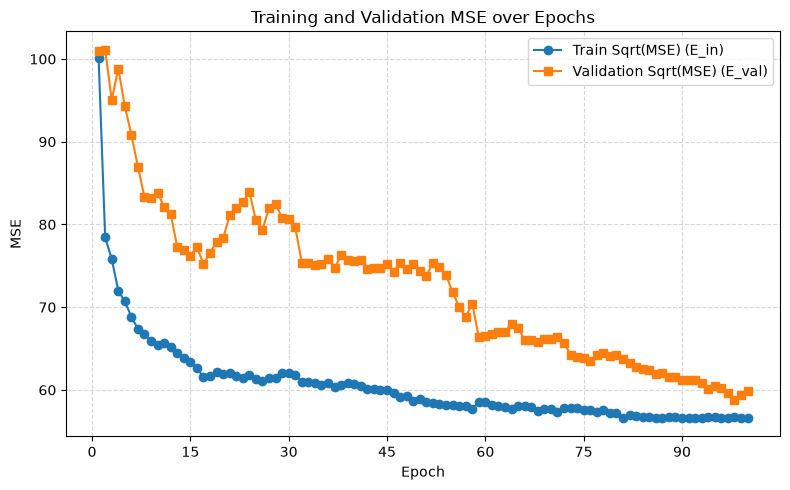

In [14]:
def run_epoch(model: nn.Module, dataloader: DataLoader, loss_fn: nn.Module, step: bool,
              optimizer: torch.optim.Optimizer | None) -> float:
    """Run one training or evaluation epoch and return the dataset-level RMSE.

        Args:
            model: Regression network producing scalar predictions per sample.
            dataloader: Batched iterable yielding `(features, targets)` tensors.
            loss_fn: Loss module evaluated on `(preds, targets)` (e.g., `nn.MSELoss`).
            step: If `True`, enables gradients and performs optimizer updates; otherwise uses `torch.no_grad()`.
            optimizer: Optimizer used when `step` is `True`; may be `None` when `step` is `False`.

        Returns:
            Root mean squared error (`math.sqrt(mse)`) averaged across all samples.
        """

    running_loss = 0.0
    total_samples = 0
    grad_ctx = nullcontext() if step else torch.no_grad()

    with grad_ctx:
        for features, targets in dataloader:
            preds = model(features).squeeze(-1)
            targets = targets.float().squeeze(-1)
            loss = loss_fn(preds, targets)

            if step:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

    mse = running_loss / total_samples
    return math.sqrt(mse)

def show_graph(history: list[tuple[float, float]]) -> None:
    """Plot training and validation error metrics across epochs.

        Args:
            history: Sequence of `(train_metric, val_metric)` tuples ordered by epoch.
        """
    epochs_range = range(1, len(history) + 1)
    e_in_vals = [pair[0] for pair in history]
    e_val_vals = [pair[1] for pair in history]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(epochs_range, e_in_vals, marker="o", label="Train Sqrt(MSE) (E_in)")
    ax.plot(epochs_range, e_val_vals, marker="s", label="Validation Sqrt(MSE) (E_val)")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=10))
    ax.set_title("Training and Validation MSE over Epochs")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
    fig.tight_layout()
    plt.show()

train_data = load_data(filename)
diabetes_dataset = DiabetesDataset(train_data[1:])

train_ds, val_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=False)
val_dataloader = DataLoader(val_ds,  batch_size=10, shuffle=False)

model = nn.Sequential(
    nn.Linear(10, 5),
    nn.ReLU(),
    nn.Linear(5, 1),
)
optimizer = torch.optim.SGD(model.parameters(), lr=0.002)

n_epochs = 100
loss_fn = nn.MSELoss()
history: list[tuple[float, float]] = []

for epoch in range(n_epochs):
    e_in = run_epoch(model, train_dataloader, loss_fn, True, optimizer)
    e_val = run_epoch(model, val_dataloader, loss_fn, False, None)
    history.append((e_in, e_val))

show_graph(history)
